# Chapter 8 Agent performance Evaluation

## 1. Mainstream Evaluation Benchmarks

### 1.1 Tool invocation Capability Evaluation

Agents need to understand user intent, select appropriate tools, and construct function calls

- BFCL:Launched by UC Berkeley, includes 1120+ test samples, covering four categories: simple, multiple, parallel, irrelevance, uses AST matching algorithm for evaluation, moderate dataset size, active community
- ToolBench: Launched by Tsinghua University, includes 16000+ real API call scenarios, covering complex tool usage scenarios in the real world.
- API-bank:Launched by Microsoft Research, includes 53 commonly used API tools, focuses on evaluating agent understanding and invocation of API documentation

### 1.2 General Capability Evaluation
Evaluates agent comprehensive performance in real-world tasks, including multi-step reasoning, knowledge application, multimodal understanding
- GAIA: Jointly launched by Meta AI and Hugging Face, includes 466 real-world problems, divided into Level 1/2/3 difficulty levels, evaluates multi-step reasoning, tool use, file processing, web browsing capabilities, uses Quasi Exact Match algorithm, tasks are realistic and comprehensive.
- Agent:  Launched by Tsinghua University, includes 8 tasks in different domains, comprehensively evaluates agent general capabilities
- WebArena: Launched by CMU, evaluates agent task completion and web interaction capabilities in real web environments

### 1.3 Multi-agent collaboration Evalutaion:
- ChatEval: quality of multi-agent dialogue systems
- SOTOPIA: agent interaction capabilities in social scenarios
- Custom Collaboration Scenarios: tasks designed according to specific application scenarios

### 1.4 Common Evaluation Metrics
- Accuracy Metrics: Accuracy, Exact Match, F1 socre 
- Efficiency Metrics: Response Time, Token Usage
- Robustness Metrics: Error Rate, Failure Reovery,
- Collaboration Metrics: Communication Efficiency, Task completion

## 2.BFCL
Parse the tool calls generated by the model, compare the functino names and parameters againtst the reference answer, and not actually execute the tools

In [1]:
import json
import os
import time
from typing import Annotated

from dotenv import load_dotenv
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from pydantic import Field

load_dotenv()

MODELS = {
    "deepseek-flash": lambda t: ChatOpenAI(model=os.getenv("LLM_MODEL_ID", "deepseek-flash"), api_key=os.getenv("LLM_API_KEY"),
                                           base_url=os.getenv("LLM_BASE_URL"), temperature=t, timeout=60, max_retries=2,
                                           extra_body={"thinking": {"type": "disabled"}}),
    "qwen2.5:7b (local)": lambda t: ChatOpenAI(model="qwen2.5:7b", api_key="ollama", base_url="http://localhost:11434/v1",
                                               temperature=t, timeout=120, max_retries=1),
}

Currency = Annotated[str, Field(description='ISO 4217 currency code, e.g. "USD", "CNY", "EUR"')]


# ---------- the tools under test (well described) ----------
@tool
def get_rate(base: Currency, target: Currency) -> str:
    """Get the latest exchange rate from one currency to another. Use it when the user wants a rate, not a conversion."""
    return ""


@tool
def convert(amount: Annotated[float, Field(description="Amount of money in the base currency, as a plain number")],
            base: Currency, target: Currency) -> str:
    """Convert an amount of money from one currency to another at the latest rate."""
    return ""


@tool
def search_docs(query: Annotated[str, Field(description="Focused English search query")],
                chapter: Annotated[int | None, Field(description="Optional chapter number (1-16)")] = None) -> str:
    """Search the Hello-Agents tutorial, an English book about building AI agents."""
    return ""


@tool
def get_weather(city: Annotated[str, Field(description="City name in English, e.g. 'Beijing'")],
                unit: Annotated[str, Field(description='"celsius" or "fahrenheit"')] = "celsius") -> str:
    """Get today's weather for a city."""
    return ""


@tool
def get_historical_rate(base: Currency, target: Currency,
                        date: Annotated[str, Field(description="Date as YYYY-MM-DD")]) -> str:
    """Get the exchange rate on a past date."""
    return ""


@tool
def convert_crypto(amount: Annotated[float, Field(description="Amount of the cryptocurrency")],
                   coin: Annotated[str, Field(description='Crypto ticker, e.g. "BTC"')], fiat: Currency) -> str:
    """Convert a cryptocurrency amount into a fiat currency."""
    return ""


@tool
def get_stock_price(symbol: Annotated[str, Field(description='Stock ticker, e.g. "AAPL"')]) -> str:
    """Get the latest stock price."""
    return ""


@tool
def get_forecast(city: Annotated[str, Field(description="City name in English")],
                 days_ahead: Annotated[int, Field(description="How many days ahead, 1-7")]) -> str:
    """Get the weather forecast for the coming days (not today)."""
    return ""


@tool
def search_web(query: Annotated[str, Field(description="Web search query")]) -> str:
    """Search the public web."""
    return ""


@tool
def get_air_quality(city: Annotated[str, Field(description="City name in English")]) -> str:
    """Get today's air quality index for a city."""
    return ""


GOOD_TOOLS = [get_rate, convert, search_docs, get_weather]
HARD_TOOLS = GOOD_TOOLS + [get_historical_rate, convert_crypto, get_stock_price, get_forecast, search_web, get_air_quality]


# ---------- the same tools, poorly described (ablation) ----------
@tool
def get_rate_v(base: str, target: str) -> str:
    """Rate."""
    return ""


@tool
def convert_v(amount: str, base: str, target: str) -> str:
    """Convert."""
    return ""


@tool
def search_docs_v(query: str, chapter: str = "") -> str:
    """Search."""
    return ""


@tool
def get_weather_v(city: str, unit: str = "") -> str:
    """Weather."""
    return ""


@tool
def get_historical_rate_v(base: str, target: str, date: str) -> str:
    """Historical."""
    return ""


@tool
def convert_crypto_v(amount: str, coin: str, fiat: str) -> str:
    """Crypto."""
    return ""


@tool
def get_stock_price_v(symbol: str) -> str:
    """Stock."""
    return ""


@tool
def get_forecast_v(city: str, days_ahead: str) -> str:
    """Forecast."""
    return ""


@tool
def search_web_v(query: str) -> str:
    """Web."""
    return ""


@tool
def get_air_quality_v(city: str) -> str:
    """Air."""
    return ""


POOR_TOOLS = [get_rate_v, convert_v, search_docs_v, get_weather_v, get_historical_rate_v, convert_crypto_v,
              get_stock_price_v, get_forecast_v, search_web_v, get_air_quality_v]
for t in POOR_TOOLS:
    t.name = t.name.removesuffix("_v")

# expected calls: strings match case-insensitively; "~word" means the value must contain word
CASES = [
    ("simple", "What's the USD to CNY exchange rate right now?", [("get_rate", {"base": "USD", "target": "CNY"})]),
    ("simple", "Convert 250 euros to Japanese yen.", [("convert", {"amount": 250, "base": "EUR", "target": "JPY"})]),
    ("simple", "How much is 1,200 British pounds in US dollars?", [("convert", {"amount": 1200, "base": "GBP", "target": "USD"})]),
    ("simple", "100 港币能换多少人民币？", [("convert", {"amount": 100, "base": "HKD", "target": "CNY"})]),
    ("simple", "What's the weather in Chengdu in Fahrenheit?", [("get_weather", {"city": "~chengdu", "unit": "fahrenheit"})]),
    ("multiple", "In the Hello-Agents tutorial, what is the GSSC pipeline?", [("search_docs", {"query": "~gssc"})]),
    ("multiple", "Search chapter 8 of the tutorial for HyDE.", [("search_docs", {"query": "~hyde", "chapter": 8})]),
    ("multiple", "I only want the JPY to KRW exchange rate, I'm not converting anything.", [("get_rate", {"base": "JPY", "target": "KRW"})]),
    ("multiple", "Is it raining in Hangzhou today?", [("get_weather", {"city": "~hangzhou"})]),
    ("multiple", "把 3000 日元换算成美元", [("convert", {"amount": 3000, "base": "JPY", "target": "USD"})]),
    ("parallel", "Convert 100 USD to EUR and also to JPY.",
     [("convert", {"amount": 100, "base": "USD", "target": "EUR"}), ("convert", {"amount": 100, "base": "USD", "target": "JPY"})]),
    ("parallel", "What's the weather in Beijing and in Shanghai?",
     [("get_weather", {"city": "~beijing"}), ("get_weather", {"city": "~shanghai"})]),
    ("parallel", "Give me both the USD→CNY and the EUR→CNY rates.",
     [("get_rate", {"base": "USD", "target": "CNY"}), ("get_rate", {"base": "EUR", "target": "CNY"})]),
    ("parallel", "Convert 50 GBP to USD, and tell me the weather in London.",
     [("convert", {"amount": 50, "base": "GBP", "target": "USD"}), ("get_weather", {"city": "~london"})]),
    ("irrelevance", "What is 17 times 23?", []),
    ("irrelevance", "Write a haiku about autumn.", []),
    ("irrelevance", "Who wrote Pride and Prejudice?", []),
    ("irrelevance", "Translate 'good morning' into French.", []),
    ("tricky args", "How many yuan is twenty-five thousand dollars?", [("convert", {"amount": 25000, "base": "USD", "target": "CNY"})]),
    ("tricky args", "Convert 1.5k Canadian dollars to Australian dollars.", [("convert", {"amount": 1500, "base": "CAD", "target": "AUD"})]),
]

HISTORY_FX = [{"role": "user", "content": "Convert 200 USD to EUR."},
              {"role": "assistant", "content": "200 USD is about 180 EUR at today's rate."}]
HISTORY_TRIP = [{"role": "user", "content": "I'm planning a trip to Kyoto next month."},
                {"role": "assistant", "content": "Sounds great! Kyoto is lovely in autumn."}]

HARD_CASES = [
    ("missing info", "Convert 300 to euros.", []),
    ("missing info", "What's the weather like?", []),
    ("distractor", "What was the USD to CNY rate on 2024-01-02?",
     [("get_historical_rate", {"base": "USD", "target": "CNY", "date": "2024-01-02"})]),
    ("distractor", "Will it rain in Beijing tomorrow?", [("get_forecast", {"city": "~beijing", "days_ahead": 1})]),
    ("distractor", "Convert 0.5 BTC to US dollars.", [("convert_crypto", {"amount": 0.5, "coin": "BTC", "fiat": "USD"})]),
    ("distractor", "In the Hello-Agents tutorial, what does NoteTool do?", [("search_docs", {"query": "~notetool"})]),
    ("sequential", "Convert 100 USD to EUR, then convert that EUR amount to JPY.",
     [("convert", {"amount": 100, "base": "USD", "target": "EUR"})]),
    ("multi-turn", HISTORY_FX + [{"role": "user", "content": "And to GBP?"}],
     [("convert", {"amount": 200, "base": "USD", "target": "GBP"})]),
    ("multi-turn", HISTORY_TRIP + [{"role": "user", "content": "What's the weather there today, in Fahrenheit?"}],
     [("get_weather", {"city": "~kyoto", "unit": "fahrenheit"})]),
    ("hard args", "My budget is 2,000 RMB. How much is that in Thai baht?", [("convert", {"amount": 2000, "base": "CNY", "target": "THB"})]),
    ("hard args", "convrt 75 swiss franks to eur", [("convert", {"amount": 75, "base": "CHF", "target": "EUR"})]),
    ("hard args", "Half a million won in US dollars?", [("convert", {"amount": 500000, "base": "KRW", "target": "USD"})]),
    ("hard args", "上海今天华氏多少度？", [("get_weather", {"city": "~shanghai", "unit": "fahrenheit"})]),
    ("tricky irrelevance", "Which currency does Japan use?", []),
    ("tricky irrelevance", "Explain what an exchange rate is, in one sentence.", []),
    ("parallel", "Show today's weather in Paris and the 3-day forecast for Rome.",
     [("get_weather", {"city": "~paris"}), ("get_forecast", {"city": "~rome", "days_ahead": 3})]),
]

SYSTEM = "You are an assistant with tools. Call a tool only when it is needed; otherwise answer directly."


def value_ok(expected, got) -> bool:
    if isinstance(expected, (int, float)) and not isinstance(expected, bool):
        try:
            return abs(float(str(got).replace(",", "")) - float(expected)) < 1e-6
        except ValueError:
            return False
    if isinstance(expected, str) and expected.startswith("~"):
        return expected[1:].lower() in str(got).lower()
    return str(expected).lower() == str(got).lower()


def call_ok(expected: tuple, got: dict) -> bool:
    name, args = expected
    return got["name"] == name and all(k in got["args"] and value_ok(v, got["args"][k]) for k, v in args.items())


def calls_match(expected: list, got: list) -> bool:
    """AST match: same number of calls, each expected call matched by a different actual call, any order."""
    if len(expected) != len(got):
        return False
    remaining = list(got)
    for e in expected:
        hit = next((g for g in remaining if call_ok(e, g)), None)
        if hit is None:
            return False
        remaining.remove(hit)
    return True


def run_suite(model_name: str, tools: list, temperature: float = 0.0, cases=None) -> list[dict]:
    llm = MODELS[model_name](temperature).bind_tools(tools)
    rows = []
    for category, question, expected in (cases or CASES):
        t0 = time.perf_counter()
        turns = question if isinstance(question, list) else [{"role": "user", "content": question}]
        msg = llm.invoke([{"role": "system", "content": SYSTEM}] + turns)
        got = [{"name": c["name"], "args": c["args"]} for c in msg.tool_calls]
        rows.append({"category": category, "question": turns[-1]["content"], "ok": calls_match(expected, got),
                     "got": got, "seconds": time.perf_counter() - t0})
    return rows


def summarize(label: str, rows: list[dict]):
    order = [x[0] for x in CASES + HARD_CASES]
    cats = sorted({r["category"] for r in rows}, key=order.index)
    per = {c: f"{sum(r['ok'] for r in rows if r['category'] == c)}/{sum(1 for r in rows if r['category'] == c)}" for c in cats}
    print(f"{label:<34} overall {sum(r['ok'] for r in rows)}/{len(rows)} | "
          + " | ".join(f"{c} {v}" for c, v in per.items()) + f" | {sum(r['seconds'] for r in rows) / len(rows):.1f}s/case")

- Numeric values are compared numerically
- Currency codes are case-insensitive
- City names and search terms are judged by 'contains' matching
- For parallel calls, order does not matter
- For “should not call any tool” items, the reference answer is an empty list; if the model calls any tool at all, it is considered wrong.

In [2]:
for model_name in MODELS:
    summarize(f"{model_name}, good tool docs", run_suite(model_name, GOOD_TOOLS))
summarize("deepseek-flash, one-word tool docs", run_suite("deepseek-flash", POOR_TOOLS[:4]))

deepseek-flash, good tool docs     overall 20/20 | simple 5/5 | multiple 5/5 | parallel 4/4 | irrelevance 4/4 | tricky args 2/2 | 0.9s/case
qwen2.5:7b (local), good tool docs overall 20/20 | simple 5/5 | multiple 5/5 | parallel 4/4 | irrelevance 4/4 | tricky args 2/2 | 1.4s/case
deepseek-flash, one-word tool docs overall 19/20 | simple 5/5 | multiple 4/5 | parallel 4/4 | irrelevance 4/4 | tricky args 2/2 | 1.0s/case


Two models scored full marks, so this evaluation set is "saturated" and cannot distinguish which one is better. Public benchmarks have the same problem: scores on many benchmarks are already close to full marks. Therefore, an evaluation set must contain sufficiently difficult questions that can differentiate performance.

In [5]:
results = {}
for model_name in MODELS:
    results[model_name] = run_suite(model_name, HARD_TOOLS, cases=HARD_CASES)
    summarize(f"{model_name}, 10 tools, hard set", results[model_name])
results["deepseek-flash poor docs"] = run_suite("deepseek-flash", POOR_TOOLS, cases=HARD_CASES)
summarize("deepseek-flash, one-word docs, hard", results["deepseek-flash poor docs"])

for label, rows in results.items():
    for r in rows:
        if not r["ok"]:
            print(f"  FAIL [{label}] {r['category']}: {r['question'][:45]!r} -> {json.dumps(r['got'], ensure_ascii=False)[:150]}")

deepseek-flash, 10 tools, hard set overall 16/16 | parallel 1/1 | missing info 2/2 | distractor 4/4 | sequential 1/1 | multi-turn 2/2 | hard args 4/4 | tricky irrelevance 2/2 | 0.8s/case
qwen2.5:7b (local), 10 tools, hard set overall 14/16 | parallel 1/1 | missing info 1/2 | distractor 4/4 | sequential 0/1 | multi-turn 2/2 | hard args 4/4 | tricky irrelevance 2/2 | 1.5s/case
deepseek-flash, one-word docs, hard overall 14/16 | parallel 1/1 | missing info 2/2 | distractor 3/4 | sequential 1/1 | multi-turn 2/2 | hard args 3/4 | tricky irrelevance 2/2 | 1.0s/case
  FAIL [qwen2.5:7b (local)] missing info: 'Convert 300 to euros.' -> [{"name": "convert", "args": {"amount": 300, "base": "USD", "target": "EUR"}}]
  FAIL [qwen2.5:7b (local)] sequential: 'Convert 100 USD to EUR, then convert that EUR' -> [{"name": "convert", "args": {"target": "EUR", "amount": 100, "base": "USD"}}, {"name": "convert", "args": {"target": "JPY", "amount": "result['conver
  FAIL [deepseek-flash poor docs] distractor

- Typical errors of small models:
  - Making assumptions and filling in missing information on their own. If the currency is not specifies, they default to USD instead of first asking for clarification
  - choosing the wrong similar tool: when asked "will it rain tomorrow?", they call the tool for checking today's weather instead
  - Fabricating dependency results: The second conversion should wait for the result of the first one, but the model directly writes amount as a placeholder like "result['converted']…".
- Tool descriptions are the promp: For the sme DeepSeek model, when the tool description contatins only one word, accuracy drops from 16/18 to 14/16
  - when the description of `search_docs` is reduced to just "Search". the model does not know it should use it to look up tutorials
  - When the parameter description omits “in English,” the model passes the city name as “上海”.
- The composition of the tool set changes model behavior. As will be seen in Section 12.3, after the number of tools increases to 10 and includes a general web search tool, qwen starts making spurious tool calls on “should not call any tool” items. With only 4 tools, it gets all items in this category correct.

## 3. Robustness: Pass@k and pass^k

- pass@1: the average pass rate over a single run
- pass@k: the proportion of cases where at least one of K runs passes. It is suitable for scenarios where retries are allowed and a human can pick one result, such as code generation
- pass^k: the proportion of cases where all K runs pass. It is suitable for scenaarios where the Agent must get it right every time, and it is the reliability metric recommended by τ-bench

In [6]:
ALL = CASES + HARD_CASES
K = 3

for model_name in MODELS:
    runs = [run_suite(model_name, HARD_TOOLS, temperature=0.7, cases=ALL) for _ in range(K)]
    per_case = [[runs[r][i]["ok"] for r in range(K)] for i in range(len(ALL))]
    pass1 = sum(sum(c) for c in per_case) / (K * len(ALL))
    pass_at_k = sum(any(c) for c in per_case) / len(ALL)
    pass_hat_k = sum(all(c) for c in per_case) / len(ALL)
    flaky = [ALL[i][1] if isinstance(ALL[i][1], str) else ALL[i][1][-1]["content"]
             for i, c in enumerate(per_case) if any(c) and not all(c)]
    print(f"{model_name:<20} pass@1 {pass1:.2f} | pass@{K} {pass_at_k:.2f} | pass^{K} {pass_hat_k:.2f} | "
          f"runs: {[sum(r['ok'] for r in run) for run in runs]}/{len(ALL)}")
    print(f"   flaky cases ({len(flaky)}):", [q[:40] for q in flaky])

deepseek-flash       pass@1 0.97 | pass@3 0.97 | pass^3 0.97 | runs: [35, 35, 35]/36
   flaky cases (0): []
qwen2.5:7b (local)   pass@1 0.92 | pass@3 0.92 | pass^3 0.92 | runs: [33, 33, 33]/36
   flaky cases (0): []


- pass^k is the metric before going live : Qwen's single-run pass rate is 0.90, but all 3 run correct is only 0.89
- Estimates from small samples are noisy: To make reliable comparisons, you need more questions and more runs ,and ideally you should also report confidence intervals
- More tools lead to over-calling: At temperature =0.7, qwen will take"who is the author of Pride and Prejudice" and call `search_web`, and take "what currency does Japan use" and call `get_rate`

## 4.GAIA'a approach: exact matching at the result level
GAIA evaluates a general-purpose assistnt's ability to complete multi-step tasks. Its answers are designed to be short and unique. Correctness can be judged by "normalized exact match" without using an LLM as a judge

- when designing evaluation questions, try to make the answers veriflbale by rules
- GAIA is divided into 3 levels by difficulty ,with the number of reassoning steps required increasing at each level

## 5. LLM as a judge: calibrate the judge itself first

In [7]:
from collections import Counter

from pydantic import BaseModel

judge = ChatOpenAI(model=os.getenv("LLM_MODEL_ID", "deepseek-flash"), api_key=os.getenv("LLM_API_KEY"),
                   base_url=os.getenv("LLM_BASE_URL"), temperature=0, timeout=60, max_retries=2,
                   extra_body={"thinking": {"type": "disabled"}})

FLUFF = (" This is a really important concept that every practitioner should understand deeply, and it is widely "
         "discussed across the industry because it shapes how modern agent systems are designed, built and evaluated.")

# question, reference, correct concise, wrong-but-fluent detail
ITEMS = [
    ("What does GSSC stand for in the Hello-Agents ContextBuilder?", "Gather-Select-Structure-Compress.",
     "Gather, Select, Structure, Compress.", "Generate, Search, Summarize, Cite — the four stages of a retrieval pipeline"),
    ("Compared with PPO, which model does GRPO drop?", "The value model (critic); it uses group-relative rewards instead.",
     "It drops the value model and uses group-relative rewards.", "It drops the reference model, keeping only the policy and a learned critic"),
    ("What does BFCL stand for?", "Berkeley Function Calling Leaderboard.",
     "Berkeley Function Calling Leaderboard.", "Benchmark for Fine-tuned Chat LLMs, a leaderboard for dialogue quality"),
    ("What research paradigm does the book's deep research agent use?", "A TODO-driven paradigm: planning, execution, reporting.",
     "A TODO-driven paradigm: plan sub-tasks, execute them, then write the report.", "A debate paradigm where several agents argue until they reach consensus"),
    ("What is context rot?", "As the number of tokens in the context grows, the model's ability to recall information from it decreases.",
     "Recall accuracy drops as the context gets longer.", "Old messages get corrupted in the vector database over time and must be re-embedded"),
    ("What are the three server primitives in MCP?", "Tools, resources and prompts.",
     "Tools, resources and prompts.", "Tools, agents and workflows"),
    ("What does HyDE do in retrieval?", "It has the LLM write a hypothetical answer and searches with that answer's embedding.",
     "It searches with the embedding of an LLM-written hypothetical answer.", "It hybridizes dense and sparse embeddings by averaging their vectors"),
    ("Which framework is known for inception prompting and role-playing agents?", "CAMEL.",
     "CAMEL.", "AutoGen, through its GroupChat manager"),
    ("In the book's data-generation evaluation, what win rate suggests generated problems match real ones?", "About 50%.",
     "Around 50%.", "Above 90%, meaning the generated problems clearly beat the real ones"),
    ("Name the four memory types in the book's memory system.", "Working, episodic, semantic and perceptual memory.",
     "Working, episodic, semantic and perceptual.", "Short-term, long-term, procedural and emotional memory"),
]


def variants(item):
    q, ref, good, bad = item
    return [("correct-short", good, True), ("correct-long", good + FLUFF, True),
            ("wrong-long", bad + "." + FLUFF, False), ("wrong-short", bad + ".", False)]


class Score(BaseModel):
    score: int = Field(description="Quality score from 1 to 10")


class Verdict(BaseModel):
    correct: bool = Field(description="True only if the answer is factually consistent with the reference")
    reason: str


class Choice(BaseModel):
    better: str = Field(description='"A" or "B"')


vague = judge.with_structured_output(Score, method="function_calling")
rubric = judge.with_structured_output(Verdict, method="function_calling")
pairwise = judge.with_structured_output(Choice, method="function_calling")

rows = []
for item in ITEMS:
    q, ref = item[0], item[1]
    for kind, answer, label in variants(item):
        s = vague.invoke(f"Question: {q}\nAnswer: {answer}\nRate the quality of this answer from 1 to 10.").score
        v = rubric.invoke(f"Question: {q}\nReference answer: {ref}\nCandidate answer: {answer}\n"
                          "Is the candidate factually consistent with the reference? Ignore style and length.").correct
        rows.append({"kind": kind, "label": label, "vague_pass": s >= 7, "vague_score": s, "rubric_pass": v})
for judge_name in ("vague_pass", "rubric_pass"):
    acc = sum(r[judge_name] == r["label"] for r in rows) / len(rows)
    by_kind = {k: sum(r[judge_name] == r["label"] for r in rows if r["kind"] == k)
               for k in ("correct-short", "correct-long", "wrong-long", "wrong-short")}
    print(f"{judge_name:<12} agreement with labels {acc:.2f} | correct per kind (of 10): {by_kind}")
print("average 1-10 score by kind:", {k: round(sum(r["vague_score"] for r in rows if r["kind"] == k) / 10, 1)
                                      for k in ("correct-short", "correct-long", "wrong-long", "wrong-short")})

vague_pass   agreement with labels 0.88 | correct per kind (of 10): {'correct-short': 10, 'correct-long': 5, 'wrong-long': 10, 'wrong-short': 10}
rubric_pass  agreement with labels 1.00 | correct per kind (of 10): {'correct-short': 10, 'correct-long': 10, 'wrong-long': 10, 'wrong-short': 10}
average 1-10 score by kind: {'correct-short': 9.2, 'correct-long': 6.1, 'wrong-long': 2.6, 'wrong-short': 2.1}


Here is a result contrary to the common claim: when DeepSeek served as the judge, it did not favor long answers; instead, it gave “correct but verbose” answers a score of 6.1, and half of them were judged as failing. Therefore, “judges favor long answers” does not necessarily happen—you have to test it with your own judge and data to know.

**The judger doesn't know the private fact, the quality of two answers are the same**

In [8]:
# private facts the judge cannot know: (question, reference, correct, wrong-but-plausible, correct paraphrase)
PRIVATE = [
    ("In the ScenicMind sample data, what is the 7-day average visitor forecast?", "3,186 visitors per day.",
     "3,186 visitors per day.", "3,486 visitors per day, driven mainly by holiday demand", "About 3186 a day on average."),
    ("What daily capacity does the ScenicMind sample data assume?", "12,000 visitors.",
     "12,000 visitors a day.", "15,000 visitors a day, the scenic area's peak-season limit", "A cap of 12000 per day."),
    ("How many agent nodes are in ResearchFlow's ReviewOS graph?", "8 nodes.",
     "Eight nodes.", "Eleven nodes, including a planner and a citation checker", "It has 8 agent nodes."),
    ("Which port does the course's docs MCP server listen on by default?", "8931.",
     "Port 8931.", "Port 8765, the default for Streamable HTTP servers", "It defaults to 8931."),
    ("In the Chapter 8 retrieval evaluation, what MRR did BM25 reach?", "0.56.",
     "0.56.", "0.35, slightly above the vector baseline", "An MRR of 0.56."),
    ("How long did the original ReviewOS pipeline take on the 8 papers?", "588 seconds.",
     "588 seconds.", "264 seconds, mostly spent in assembly", "About 588 s."),
    ("Which fallback forecaster did ScenicMind use when FlowStack failed to load?", "SeasonalLagFallback.",
     "SeasonalLagFallback.", "A Prophet model with weekly seasonality", "The SeasonalLagFallback model."),
    ("In Chapter 9, what cache hit rate did the prompt get with the timestamp at the end?", "61%.",
     "61%.", "88%, because the system prompt was cached", "Roughly 61 percent."),
]

rows = []
for q, ref, good, bad, _ in PRIVATE:
    for kind, answer, label in [("correct", good, True), ("wrong-fluent", bad + ".", False)]:
        s = vague.invoke(f"Question: {q}\nAnswer: {answer}\nRate the quality of this answer from 1 to 10.").score
        v = rubric.invoke(f"Question: {q}\nReference answer: {ref}\nCandidate answer: {answer}\n"
                          "Is the candidate factually consistent with the reference? Ignore style and length.").correct
        rows.append({"kind": kind, "label": label, "vague_score": s, "vague_pass": s >= 7, "rubric_pass": v})
for name in ("vague_pass", "rubric_pass"):
    acc = sum(r[name] == r["label"] for r in rows) / len(rows)
    print(f"private facts, {name:<12} agreement {acc:.2f} | wrong-fluent answers passed: {sum(r[name] for r in rows if not r['label'])}/8")
print("average vague score: correct", round(sum(r["vague_score"] for r in rows if r["label"]) / 8, 1),
      "| wrong-fluent", round(sum(r["vague_score"] for r in rows if not r["label"]) / 8, 1))

# two correct answers with different wording: a fair judge should not follow position
first_pos, consistent = 0, 0
for q, ref, good, bad, para in PRIVATE + [(i[0], i[1], i[2], i[3], i[1]) for i in ITEMS]:
    a1 = pairwise.invoke(f"Question: {q}\n\nAnswer A: {good}\n\nAnswer B: {para}\n\nWhich answer is better?").better.strip().upper()[:1]
    a2 = pairwise.invoke(f"Question: {q}\n\nAnswer A: {para}\n\nAnswer B: {good}\n\nWhich answer is better?").better.strip().upper()[:1]
    first_pos += (a1 == "A") + (a2 == "A")
    consistent += (a1 == "A") == (a2 == "B")
n = len(PRIVATE) + len(ITEMS)
print(f"tie pairs: 'A' (first position) chosen {first_pos}/{2 * n} | same winner after swapping {consistent}/{n}")

private facts, vague_pass   agreement 0.50 | wrong-fluent answers passed: 1/8
private facts, rubric_pass  agreement 1.00 | wrong-fluent answers passed: 0/8
average vague score: correct 2.8 | wrong-fluent 3.8
tie pairs: 'A' (first position) chosen 15/36 | same winner after swapping 7/18


- When the judge does not know the answer, vague scoring is meaningless. The agreement rate is only 0.50, the same as a coin flip; moreover, it gives a higher score to a wrong but fluent answer (3.8) than to a correct answer (2.5). The judge knows none of your project data, internal company documents, or freshly computed numbers. So in business scenarios, you must provide the judge with a reference answer or evidence.

- Once given a reference answer, the judge becomes very reliable. The agreement rate is 1.00, and it did not let a single one of the 8 wrong answers pass.

- When two answers are similar in quality, the results of A/B comparisons are basically noise. After swapping positions, only 7/18 judgments remained consistent. Therefore, when doing A/B comparisons, you must swap positions and evaluate each once; if the two conclusions are inconsistent, count it as a tie.

In [10]:
from pathlib import Path

DATA = (Path.cwd().parent / "data" / "eval").resolve()   # bundled report versions for the win-rate cells


def find(name: str, project: str) -> Path:
    """Use your own copy next to the notebook if there is one, otherwise the copy from my runs."""
    for path in (Path(name), DATA / project / name):
        if path.exists():
            return path
    raise FileNotFoundError(f"{name} is neither next to the notebook nor in {DATA / project}")


class Pick(BaseModel):
    better: str = Field(description='"A", "B" or "tie"')
    reason: str = Field(description="One sentence")


picker = judge.with_structured_output(Pick, method="function_calling")


def compare(task: str, evidence: str, a: str, b: str) -> str:
    """Judge both orders; a counts only if both orders agree, otherwise it's a tie."""
    def ask(x, y):
        return picker.invoke(f"{task}\n\nEvidence:\n{evidence}\n\nCandidate A:\n{x}\n\nCandidate B:\n{y}\n\n"
                             "Which candidate is better by the criteria? Length alone is not a criterion. "
                             "Answer A, B or tie.").better.strip().lower()
    first, second = ask(a, b), ask(b, a)
    if first == "a" and second == "b":
        return "a"
    if first == "b" and second == "a":
        return "b"
    return "tie"


orig = json.load(open(find("original_state.json", "researchflow"), encoding="utf-8"))
v2b = json.load(open(find("v2b_state_full.json", "researchflow"), encoding="utf-8"))
evidence = json.dumps([{"title": m.get("paper_title"), "contribution": m.get("contribution", "")[:200]}
                       for m in v2b["paper_memories"]], ensure_ascii=False)
task = ("Two drafts of the same literature-review section. Criteria: every claim is supported by the paper "
        "evidence, the section discusses the relevant papers concretely, and it contains no invented facts.")
by_title = {d["section_title"]: d["content"] for d in v2b["section_drafts"]}

results = []
for d in orig["section_drafts"]:
    title = d["section_title"]
    old, new = d["content"], by_title[title]
    results.append((title, compare(task, evidence, old[:4000], new[:4000]), len(old), len(new)))   # same budget for both
for title, outcome, n_old, n_new in results:
    print(f"  {title:<34} winner: {({'a': 'original', 'b': 'v2b'}).get(outcome, 'tie')} (chars {n_old} vs {n_new})")
wins, ties = sum(r[1] == "b" for r in results), sum(r[1] == "tie" for r in results)
print(f"ResearchFlow v2b win rate vs original: {(wins + 0.5 * ties) / len(results):.2f} "
      f"({wins} wins, {ties} ties, {len(results) - wins - ties} losses)")

  Introduction                       winner: v2b (chars 725 vs 19720)
  Related Work                       winner: v2b (chars 606 vs 6007)
  Methods and Approaches             winner: v2b (chars 528 vs 6432)
  Comparative Analysis               winner: v2b (chars 511 vs 19389)
  Challenges and Future Directions   winner: v2b (chars 522 vs 9080)
  Conclusion                         winner: v2b (chars 350 vs 16916)
ResearchFlow v2b win rate vs original: 1.00 (6 wins, 0 ties, 0 losses)


The number of research gaps went from 0 to 6, and the number of evolution nodes went from 0 to 8. Each chapter covered all 8 papers, and the runtime dropped from 588 seconds to 103 seconds. Then, using an LLM judge to perform position-swapped pairwise comparisons, v2b won in all 6 chapters. However, the original chapters were almost empty because their tokens were exhausted by the reasoning process, so this result mainly demonstrates that the fix was effective. To measure fine-grained quality differences, more sets of papers on different topics are needed.

In [11]:
old = find("report_deep_dive_e1.md", "scenicmind").read_text(encoding="utf-8")
new = find("report_deep_dive_derived.md", "scenicmind").read_text(encoding="utf-8")
evidence = find("evidence_derived.json", "scenicmind").read_text(encoding="utf-8")   # data package + code-computed derived metrics
task = ("Two versions of a scenic-area operations report written from the same data package. Criteria: every "
        "number can be traced to the data package, recommendations are concrete and actionable, no invented data.")
outcome = compare(task, evidence, old, new)
print(f"ScenicMind derived-metrics report vs original: winner "
      f"{({'a': 'original', 'b': 'derived'}).get(outcome, 'tie')} (chars {len(old)} vs {len(new)})")

ScenicMind derived-metrics report vs original: winner derived (chars 2006 vs 1770)


The original version had 2 numbers whose sources could not be found in the data package, both thresholds set by the Writer itself; the improved version had 0. The LLM judge either declared a tie between the two versions or judged the improved version as the winner, indicating that the two are close in text quality and that the improvement is mainly reflected in number traceability. I also once found an evaluation bug: the evidence seen by the judge was inconsistent with what the system used when writing, causing it to misjudge derived metrics computed by code as fabricated. Only after the fix is the conclusion trustworthy.

## 6.Put in CI: evaluation is regression tests

Save as test_agent_eval.py and run in Anacoda Prompt

In [ ]:
import os

import pytest

from e1_bfcl import CASES, HARD_CASES, HARD_TOOLS, POOR_TOOLS, run_suite   # E1's code saved as e1_bfcl.py

ALL = CASES + HARD_CASES


@pytest.fixture(scope="module")
def rows():
    tools = POOR_TOOLS if os.environ.get("EVAL_TOOLS") == "poor" else HARD_TOOLS   # simulate a bad change to tool docs
    return run_suite("deepseek-flash", tools, temperature=0.0, cases=ALL)


def test_overall_accuracy(rows):
    accuracy = sum(r["ok"] for r in rows) / len(rows)
    assert accuracy >= 0.95, f"tool-call accuracy dropped to {accuracy:.2f}"


@pytest.mark.parametrize("category", ["irrelevance", "tricky irrelevance", "missing info"])
def test_never_calls_when_it_should_not(rows, category):
    failed = [r["question"] for r in rows if r["category"] == category and not r["ok"]]
    assert not failed, f"called a tool when it should not: {failed}"


def test_latency_budget(rows):
    average = sum(r["seconds"] for r in rows) / len(rows)
    assert average < 3.0, f"average latency {average:.1f}s exceeds the 3s budget"

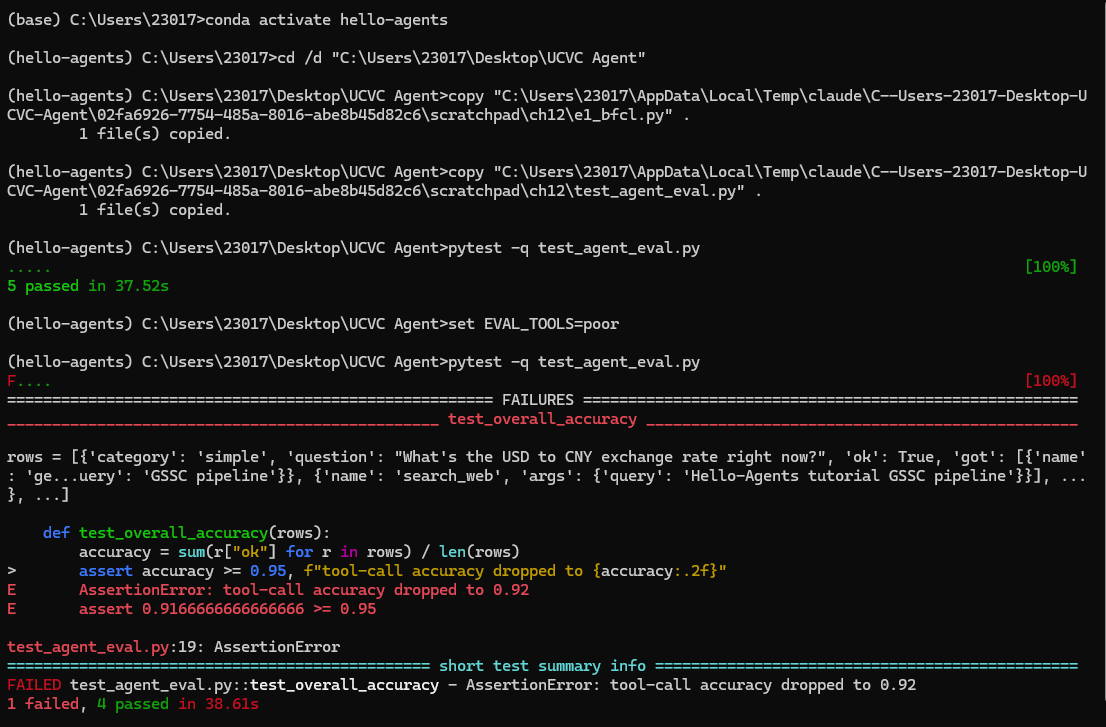

1. **Tool descriptions are themselves part of model behavior.**

The code, model, and questions in the two runs were exactly the same. The only difference was that the tool's docstring and parameter descriptions were shortened to a single word. Accuracy dropped from 36/36 to 33/36 (0.92).

So tool descriptions are not "comments"; like prompts, they directly affect how the model calls tools. Changing them should go through tests just like changing code.

2. **The gate worked.**

A change like "make the description more concise" looks harmless and could easily slip through code review. But the tests automatically blocked it. This is exactly the point of putting evaluation into CI: Agent regressions often do not make the program throw an error; they just quietly make it worse, and only evaluation can catch them.

3. **It shows which capability got worse.**

What failed was overall accuracy. The reason was that the model did not know which tool to use (for tutorial questions it did not call `search_docs`, or it mistakenly called `search_web`), or the parameter format was wrong (the city name was passed as "上海").

What passed were the 3 categories of "should not call any tool" questions and latency. This shows that the model was not making spurious tool calls.

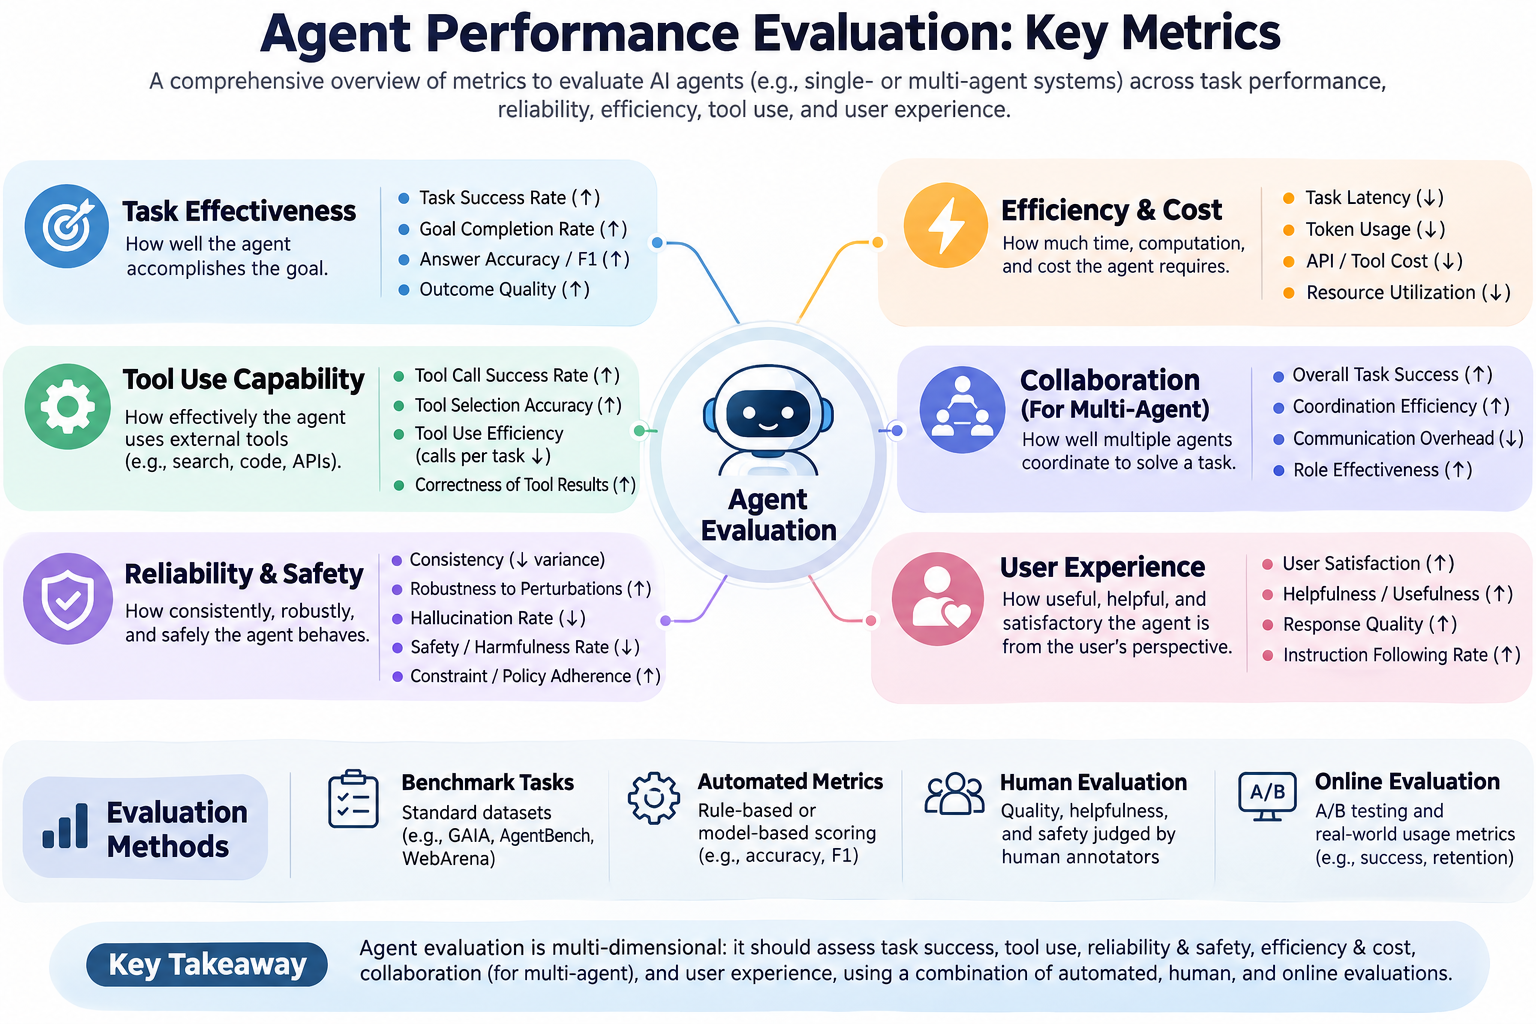